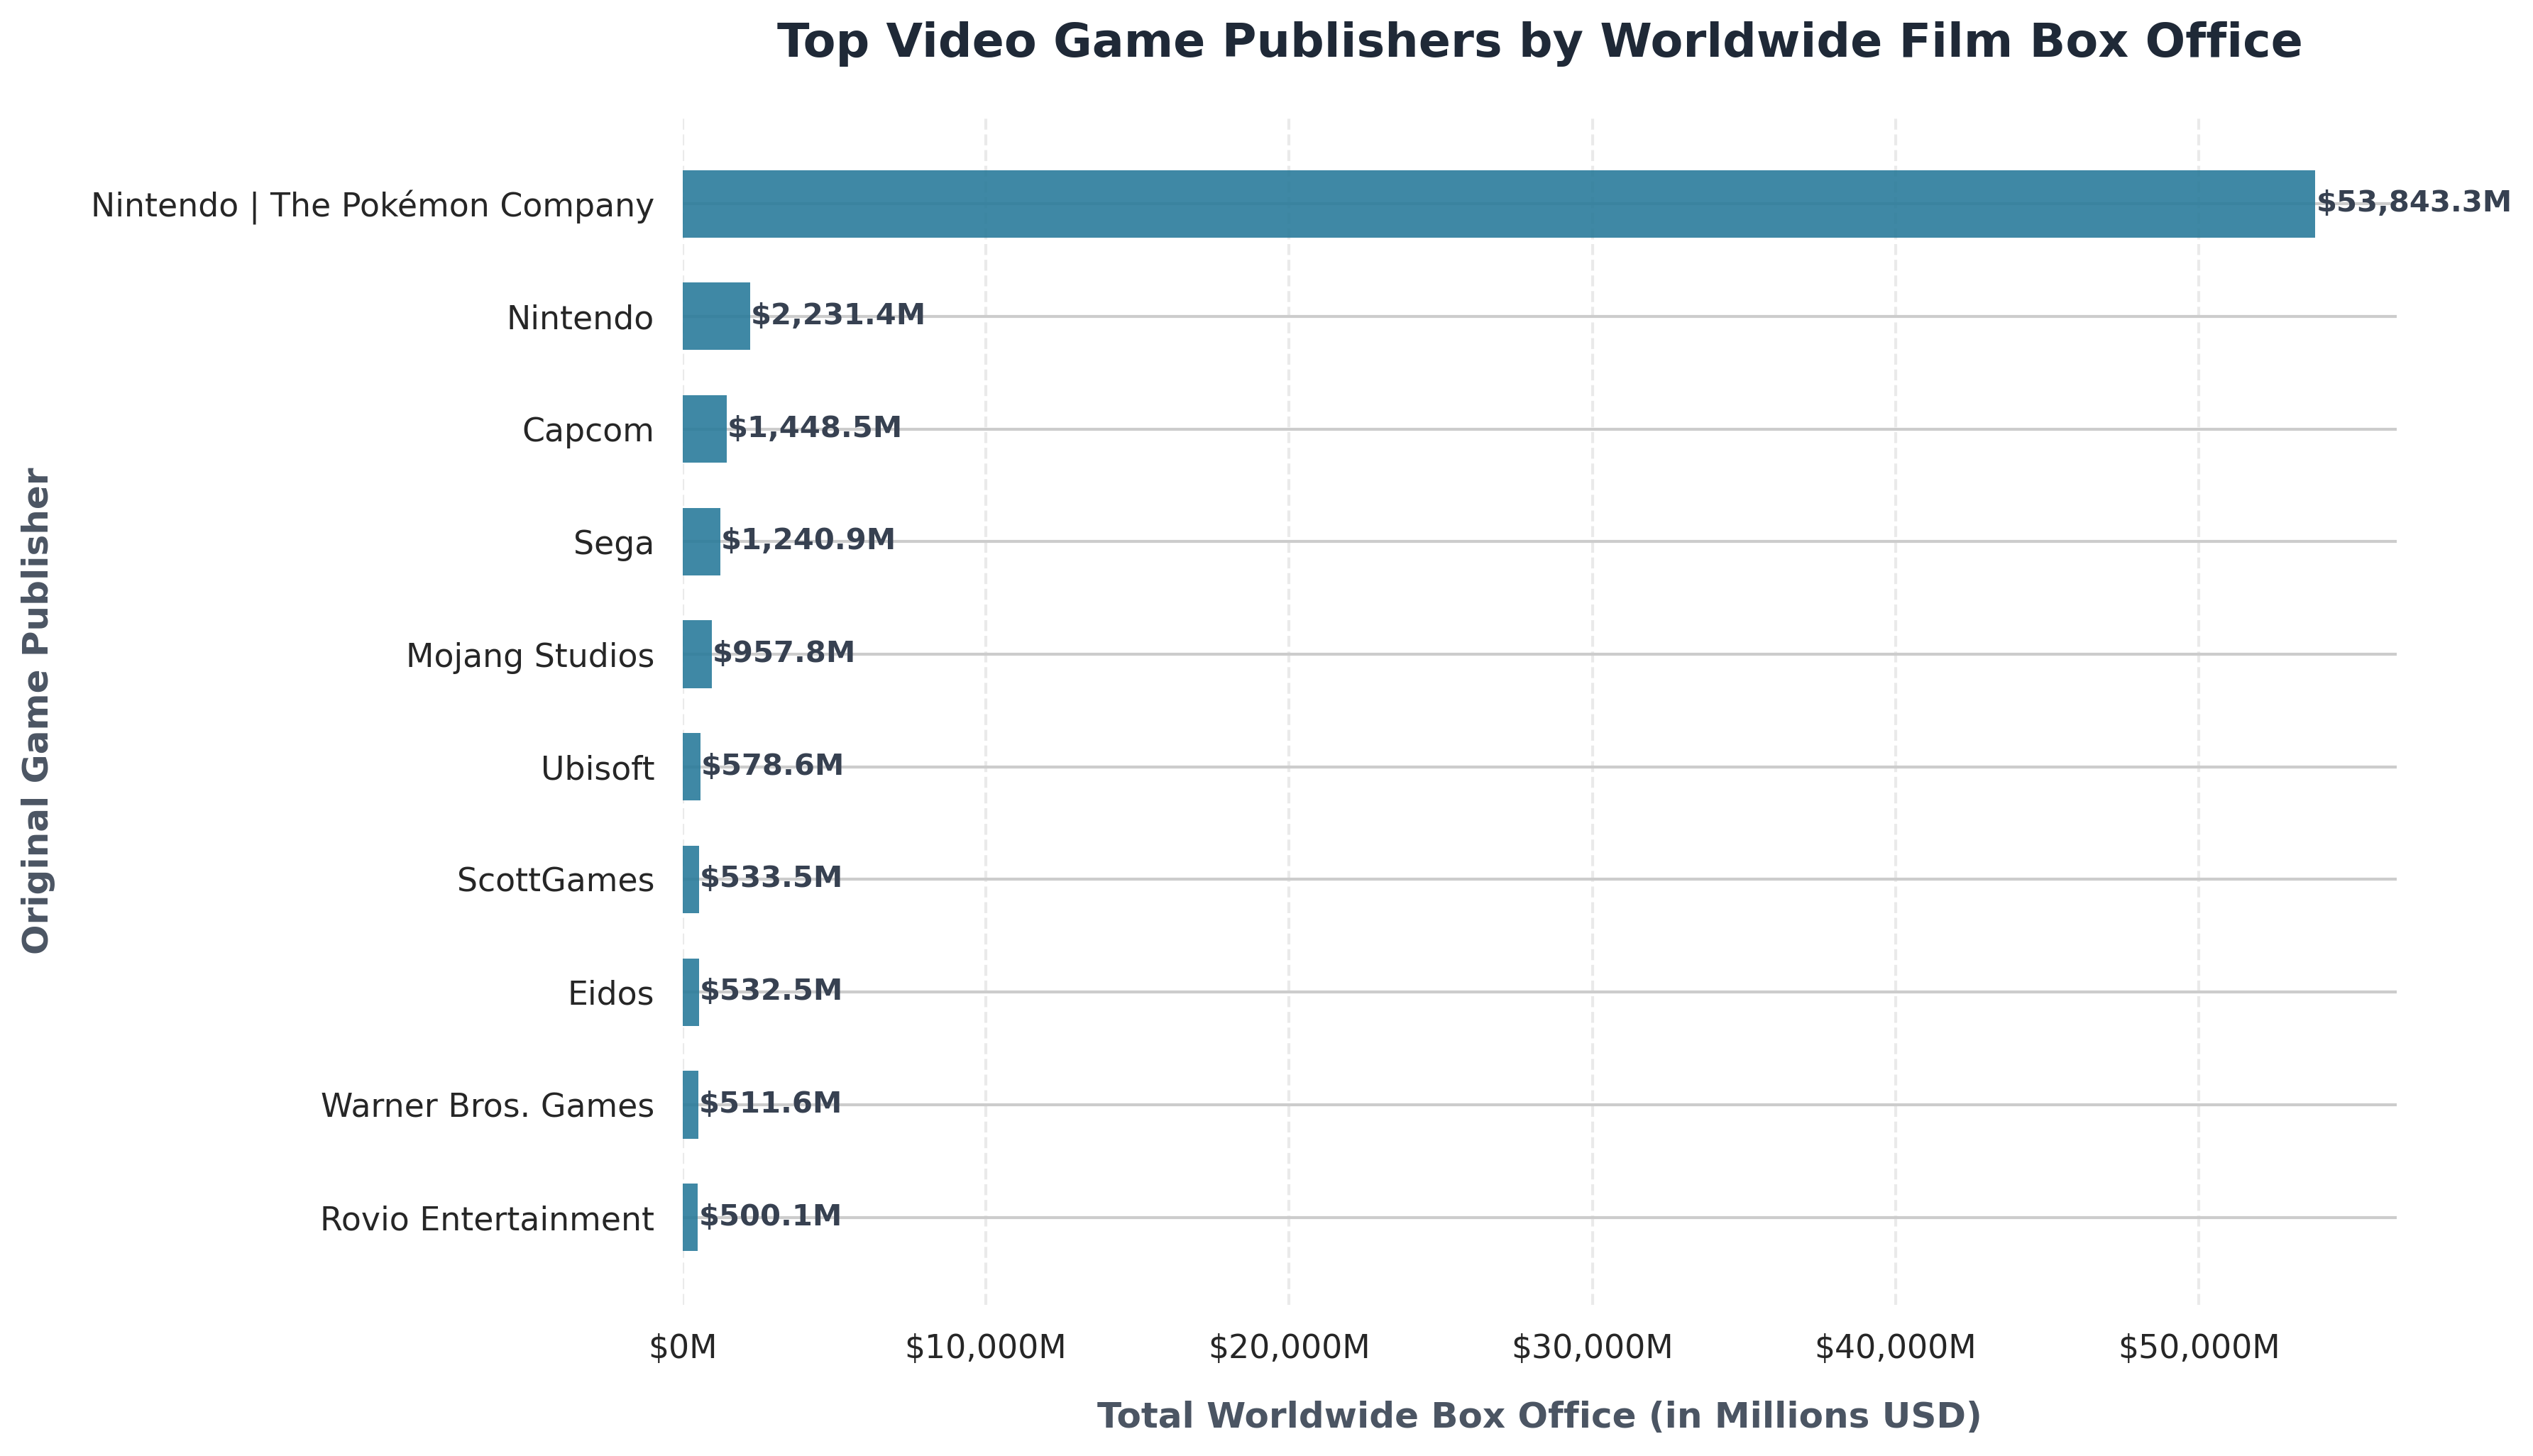

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the dataset directly from GitHub
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-06-09/game_films.csv"
df = pd.read_csv(url)

# 2. Data Cleaning & Aggregation
# Filter out rows with missing publisher or box office data, assuming USD or standardizing (or filtering for currency if needed)
# Let's aggregate by original game publisher
publisher_stats = (
    df.dropna(subset=['original_game_publisher', 'worldwide_box_office'])
    .groupby('original_game_publisher')
    .agg(
        total_box_office=('worldwide_box_office', 'sum'),
        film_count=('title', 'count'),
        avg_rt=('rotten_tomatoes', 'mean'),
    )
    .reset_index()
)

# Convert box office totals to millions for readable axis labels
publisher_stats['box_office_millions'] = (
    publisher_stats['total_box_office'] / 1e6
)

# Select the top 10 publishers by box office earnings
top_publishers = publisher_stats.sort_values(
    by='total_box_office', ascending=False
).head(10)

# 3. Setting up the visualization style
sns.set_theme(style='whitegrid', font='sans-serif')
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)

# Custom color palette (sleek modern slate blue)
bar_color = '#2A7B9B'

# Create horizontal bar chart
bars = ax.barh(
    top_publishers['original_game_publisher'][::-1],
    top_publishers['box_office_millions'][::-1],
    color=bar_color,
    edgecolor='none',
    height=0.6,
    alpha=0.9,
)

# 4. Styling titles, labels, and axes
ax.set_title(
    'Top Video Game Publishers by Worldwide Film Box Office',
    fontsize=16,
    fontweight='bold',
    pad=20,
    color='#1F2937',
)
ax.set_xlabel(
    'Total Worldwide Box Office (in Millions USD)',
    fontsize=12,
    labelpad=12,
    color='#4B5563',
    fontweight='semibold',
)
ax.set_ylabel(
    'Original Game Publisher',
    fontsize=12,
    labelpad=12,
    color='#4B5563',
    fontweight='semibold',
)

# Format X-axis with currency and comma separators
ax.xaxis.set_major_formatter('${x:,.0f}M')

# Add direct data labels to the end of each bar
for bar in bars:
  width = bar.get_width()
  ax.text(
      width + 25,
      bar.get_y() + bar.get_height() / 2,
      f'${width:,.1f}M',
      va='center',
      ha='left',
      fontsize=10,
      color='#374151',
      fontweight='bold',
  )

# Clean aesthetics (remove unnecessary spines)
sns.despine(left=True, bottom=True)
ax.grid(axis='x', linestyle='--', alpha=0.4)

# Adjust layout and show plot
plt.tight_layout()
plt.show()